# 02 — Adding a service demand

This example adds the `cook` demand and the competing `electric_stove` and `gas_stove` technologies. It uses its own model copy and results folder.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

results_dir = Path(r"C:\Users\abduq\Desktop\SSD\MUSE-Tutorials\02-Adding-a-service-demand\model\Results")
mca_capacity = pd.read_csv(results_dir / "MCACapacity.csv")
mca_capacity.head()

,agent,capacity,dst_region,installed,region,sector,technology,type,year
0,A1,10.0000,r1,2020,r1,residential,gas_stove,newcapa,2020
1,A1,10.0000,r1,2020,r1,residential,gasboiler,newcapa,2020
2,A1,1.0000,r1,2020,r1,power,gasCCGT,newcapa,2020
3,A1,15.0000,r1,2020,r1,gas,gassupply1,newcapa,2020
4,A1,7.5938,r1,2025,r1,residential,electric_stove,newcapa,2025


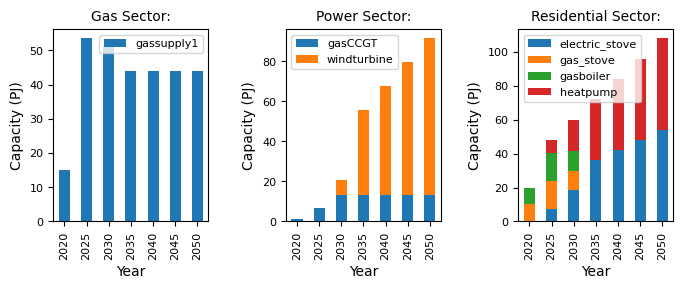

In [2]:
all_years = sorted(mca_capacity["year"].unique())
sectors = list(mca_capacity.groupby("sector"))
fig, axes = plt.subplots(1, len(sectors), squeeze=False)

for ax, (sector_name, sector_data) in zip(axes[0], sectors):
    sector_capacity = sector_data.groupby(
        ["year", "technology"], as_index=False
    )["capacity"].sum()
    sector_capacity.pivot(
        index="year", columns="technology", values="capacity"
    ).reindex(all_years, fill_value=0).plot(kind="bar", stacked=True, ax=ax)
    ax.set_ylabel("Capacity (PJ)")
    ax.set_xlabel("Year")
    ax.set_title(f"{sector_name.capitalize()} Sector:", fontsize=10)
    ax.legend(title=None, prop={"size": 8})
    ax.tick_params(axis="both", labelsize=8)

fig.set_size_inches(8, 2.5)
fig.subplots_adjust(wspace=0.5)
fig.savefig(results_dir / "MCACapacity.png", dpi=150, bbox_inches="tight")
plt.show()